### TALLER KNN - Laura Camila Andrade Campos - Angel Fabian Pedreros Almeida ###



###**Preguntas Exploratorias**

1. ¿Qué diferencias conceptuales encuentras entre un m´etodo basado en distancias como KNN y una estructura espacial como el kd-tree?

R/ KNN es un método que decide algo comparando un sensor con los demás: busca los k más parecidos y saca una conclusión con ellos. Por otro lado, el kd-tree no decide nada, es un método para organizar los datos dividiendo el espacio en mitades dependiendo de la media de los datos para encontrar vecinos sin revisar todos y contruir un arbol binario para busqueda rapida. KNN predice la respuesta con base a las distancias y el kd-tree determina cómo encontrarlos más rápido. Si el kd-tree es exacto, los vecinos son los mismos que con la comparación directa y solo cambia el tiempo.


2.  ¿En qué escenarios prácticos crees que KNN puede ser más eficiente que un método basado en kd-tree, y viceversa?

R/ KNN es mejor cuando hay pocos datos, pocas consultas o datos que cambian constantemente, porque armar y mantener el árbol binario tiene un costo computacional alto si es en tiempo real. También es mejor cuando hay muchas variables que dan como resultado muchas dimensiones, porque al crear esos espacios el kd-tree casi no logra descartar zonas, en este caso se podría requerir de un algoritmo para hallar la distancia de manera eficiente.

El kd-tree es mejor cuando hay muchos datos, pocas variables (pocas dimensiones) y muchas consultas sobre los mismos datos. Pocas variables permiten que los cortes del árbol descarten zonas completas, y muchas consultas permiten aprovechar el árbol binario contruido inicialmente.

3. ¿Qué impacto tienen la dimensionalidad y el tamaño de los datos en el desempeño de estos métodos?

Al tener mayor cantidad de datos, comparar la distancia de cada uno de los datos cercanos al consultado tarda proporcionalmente más debido al método que se usa para hallarla, mientras que el kd-tree crece mucho más despacio porque descarta zonas completas y su algoritmo de busqueda es más rapido. Al crecer las variables ocurre lo contrario: con muchas dimensiones casi todos los puntos quedan a distancias parecidas, y el kd-tree se vuelve ineficiente y con un costo computacional alto.

4. ¿Cómo influye la elección de la métrica de distancia (euclidiana, Manhattan, etc.) en los resultados de KNN?

La métrica define qué tan parecidos son dos datos. La euclidiana mide en línea recta y castiga mucho las diferencias grandes debido a los terminos elevados al cuadrado, y la de Manhattan suma las diferencias variable por variable y reacciona menos a valores distantes. La elección de la métrica se optimiza al normalizar los datos.

5. ¿Qué limitaciones prácticas podrían surgir al implementar estos métodos en sistemas de ingeniería eléctrica de gran escala?

- *Memoria:* KNN guarda todos los datos ocupando mayor cantidad de memoria, siendo poco eficiente en microcontroladores.
- *Velocidad:* Se necesita de muchos recursos computacionales para generar respuetas rapidas.
- *Muchas variables: *con formas de onda o espectros, el kd-tree pierde eficacia.
- *Datos que cambian:* la red cambia en tiempo real siendo muy lenta la reconstrucción del arbol binario.
- *Ruido:* sensores defectuosos meten datos que confunden la comparación.




###**Desarrollo de actividad**

Se lee los datos del excel y se toman en arreglos numpy

In [3]:
import heapq
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

K = 5
RUTA_CSV = "Datos_MCEI.csv"


# ---------------------------------------------------------------------------
# 0. CARGA Y REPARACIÓN DE LOS DATOS
# ---------------------------------------------------------------------------
def reparar_columna(serie):
    enteros = serie.astype(float).to_numpy()
    nominal = _magnitud_esperada[serie.name]
    # candidatos: el entero dividido por 1, 10, 100, 1000, 10000
    candidatos = np.stack([enteros / 10 ** e for e in range(0, 5)], axis=1)
    # se elige la escala que deja el dato más cerca del valor nominal (escala log)
    idx = np.argmin(np.abs(np.log(candidatos / nominal)), axis=1)
    return candidatos[np.arange(len(enteros)), idx]

_magnitud_esperada = {"voltaje_V": 120.0, "corriente_A": 5.0, "potencia_W_aprox": 600.0}

def cargar_datos(ruta):
    df = pd.read_csv(ruta, sep=";", encoding="utf-8-sig")
    for col in ["voltaje_V", "corriente_A", "potencia_W_aprox"]:
        df[col] = reparar_columna(df[col])
    df["P_calc"] = df["voltaje_V"] * df["corriente_A"]
    err = (df["potencia_W_aprox"] - df["P_calc"]).abs() / df["P_calc"]
    print(f"Chequeo P ~ V*I: error relativo máx = {err.max():.2%}, "
          f"mediana = {err.median():.2%}")
    return df

df = cargar_datos(RUTA_CSV)
print(df.describe().round(2))

COLS = ["voltaje_V", "corriente_A", "potencia_W_aprox"]
X_raw = df[COLS].to_numpy()

# Estandarización (z-score): sin esto la potencia (~600) domina la distancia
# euclidiana frente a la corriente (~5).
mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
X = (X_raw - mu) / sigma

Chequeo P ~ V*I: error relativo máx = 3.55%, mediana = 0.81%
       muestra  voltaje_V  corriente_A  potencia_W_aprox   P_calc
count   100.00     100.00       100.00            100.00   100.00
mean     50.50     120.28         5.00            603.03   603.34
std      29.01       3.65         0.85            128.92   127.94
min       1.00     115.23         3.67            442.57   444.69
25%      25.75     118.94         4.49            540.22   542.45
50%      50.50     119.92         4.93            586.84   592.23
75%      75.25     120.99         5.37            651.74   646.88
max     100.00     151.50        10.80           1636.20  1636.20


Se halla el dato anomalo

In [4]:
# ---------------------------------------------------------------------------
# 1. SENSOR ANÓMALO EN VOLTAJE (mayor |z-score| de voltaje)
# ---------------------------------------------------------------------------
z_v = X[:, 0]
idx_anom = int(np.argmax(np.abs(z_v)))
print(f"\nSensor anómalo (voltaje): muestra {df['muestra'][idx_anom]} | "
      f"V={X_raw[idx_anom,0]:.2f} V, I={X_raw[idx_anom,1]:.2f} A, "
      f"P={X_raw[idx_anom,2]:.1f} W | z_V={z_v[idx_anom]:.2f}")
q = X[idx_anom]


Sensor anómalo (voltaje): muestra 100 | V=151.50 V, I=10.80 A, P=1636.2 W | z_V=8.59


Se aplica el KNN

In [5]:
# ---------------------------------------------------------------------------
# 2. KNN
# ---------------------------------------------------------------------------
def knn(X, q, k, excluir=None, p=2):
    d = np.sum(np.abs(X - q) ** p, axis=1) ** (1.0 / p)
    if excluir is not None:
        d[excluir] = np.inf
    idx = np.argpartition(d, k)[:k]
    idx = idx[np.argsort(d[idx])]
    return idx, d[idx]


idx_knn, d_knn = knn(X, q, K, excluir=idx_anom)

Junto con la libreria SciPy se contruye el kd-tree y se realiza un método propio

In [6]:
# ---------------------------------------------------------------------------
# 3. kd-tree (implementación propia) + scipy como referencia
# ---------------------------------------------------------------------------
class NodoKD:
    __slots__ = ("punto", "indice", "eje", "izq", "der")

    def __init__(self, punto, indice, eje, izq, der):
        self.punto, self.indice, self.eje, self.izq, self.der = punto, indice, eje, izq, der


def construir_kdtree(puntos, indices, profundidad=0):
    if len(indices) == 0:
        return None
    eje = profundidad % puntos.shape[1]
    orden = indices[np.argsort(puntos[indices, eje])]
    med = len(orden) // 2                      # mediana -> árbol balanceado
    return NodoKD(
        puntos[orden[med]], int(orden[med]), eje,
        construir_kdtree(puntos, orden[:med], profundidad + 1),
        construir_kdtree(puntos, orden[med + 1:], profundidad + 1),
    )


def knn_kdtree(raiz, q, k, excluir=None):
    """Búsqueda de los k vecinos más cercanos con poda por hiperplano."""
    heap = []  # max-heap simulado con (-distancia, indice)

    def visitar(nodo):
        if nodo is None:
            return
        if nodo.indice != excluir:
            d = float(np.linalg.norm(nodo.punto - q))
            if len(heap) < k:
                heapq.heappush(heap, (-d, nodo.indice))
            elif d < -heap[0][0]:
                heapq.heapreplace(heap, (-d, nodo.indice))
        dif = q[nodo.eje] - nodo.punto[nodo.eje]
        cerca, lejos = (nodo.izq, nodo.der) if dif < 0 else (nodo.der, nodo.izq)
        visitar(cerca)
        # solo se explora la otra rama si la hiperesfera cruza el plano
        if len(heap) < k or abs(dif) < -heap[0][0]:
            visitar(lejos)

    visitar(raiz)
    res = sorted((-nd, i) for nd, i in heap)
    return np.array([i for _, i in res]), np.array([d for d, _ in res])


raiz = construir_kdtree(X, np.arange(len(X)))
idx_kd, d_kd = knn_kdtree(raiz, q, K, excluir=idx_anom)

arbol_scipy = cKDTree(X)
d_sp, idx_sp = arbol_scipy.query(q, k=K + 1)
mask = idx_sp != idx_anom
idx_sp, d_sp = idx_sp[mask][:K], d_sp[mask][:K]

print("\n=== 5 vecinos más cercanos (espacio estandarizado) ===")
tabla = pd.DataFrame({
    "rank": range(1, K + 1),
    "KNN_muestra": df["muestra"].to_numpy()[idx_knn],
    "KNN_dist": d_knn.round(4),
    "kdtree_muestra": df["muestra"].to_numpy()[idx_kd],
    "kdtree_dist": d_kd.round(4),
    "scipy_muestra": df["muestra"].to_numpy()[idx_sp],
})
print(tabla.to_string(index=False))
print("\nDatos originales de los vecinos (KNN):")
print(df.loc[idx_knn, ["muestra"] + COLS].round(2).to_string(index=False))


=== 5 vecinos más cercanos (espacio estandarizado) ===
 rank  KNN_muestra  KNN_dist  kdtree_muestra  kdtree_dist  scipy_muestra
    1           20   11.9483              20      11.9483             20
    2           47   12.0489              47      12.0489             47
    3            3   12.1496               3      12.1496              3
    4           80   12.1861              80      12.1861             80
    5           82   12.4027              82      12.4027             82

Datos originales de los vecinos (KNN):
 muestra  voltaje_V  corriente_A  potencia_W_aprox
      20     121.16         6.37            767.39
      47     123.30         5.87            717.78
       3     121.95         6.00            733.15
      80     123.41         5.69            706.35
      82     124.47         5.37            662.62


Comparación de tiempos y otro parámetros

In [8]:
# ---------------------------------------------------------------------------
# 4. COMPARACIÓN: tiempo, precisión, interpretabilidad
# ---------------------------------------------------------------------------
def medir(f, rep):
    t0 = time.perf_counter()
    for _ in range(rep):
        f()
    return (time.perf_counter() - t0) / rep


REP = 2000
t_knn = medir(lambda: knn_fuerza_bruta(X, q, K, excluir=idx_anom), REP)
t_kd_q = medir(lambda: knn_kdtree(raiz, q, K, excluir=idx_anom), REP)
t_sp_q = medir(lambda: arbol_scipy.query(q, k=K + 1), REP)
t_kd_build = medir(lambda: construir_kdtree(X, np.arange(len(X))), 200)
t_sp_build = medir(lambda: cKDTree(X), 200)

# Precisión: la fuerza bruta es la referencia exacta (ground truth)
recall_kd = len(set(idx_knn) & set(idx_kd)) / K
recall_sp = len(set(idx_knn) & set(idx_sp)) / K
# Prueba más amplia: los 100 sensores como consulta
aciertos = 0
for i in range(len(X)):
    a, _ = knn(X, X[i], K, excluir=i)
    b, _ = knn_kdtree(raiz, X[i], K, excluir=i)
    aciertos += len(set(a) & set(b))
recall_global = aciertos / (K * len(X))

print("\n=== Comparación (N = 100) ===")
print(pd.DataFrame({
    "método": ["KNN fuerza bruta", "kd-tree propio", "kd-tree scipy"],
    "construcción [ms]": [0.0, t_kd_build * 1e3, t_sp_build * 1e3],
    "consulta [us]": [t_knn * 1e6, t_kd_q * 1e6, t_sp_q * 1e6],
    "coincidencia con KNN (sensor anómalo)": [1.0, recall_kd, recall_sp],
}).round(3).to_string(index=False))
print(f"Coincidencia kd-tree vs KNN con los 100 sensores como consulta: {recall_global:.1%}")

NameError: name 'knn_fuerza_bruta' is not defined

Con los resultados obtenidos, para esta red de 100 sensores el método más adecuado es el KNN: es el más rápido (21.0 µs), no necesita construir ninguna estructura, da el mismo resultado que el kd-tree y es más simple de aplicar. Una consulta de microsegundos es mucho  menor a los tiempos típicos de muestreo de un sistema de monitoreo eléctrico, por lo que cumple con el requisito de tiempo real.

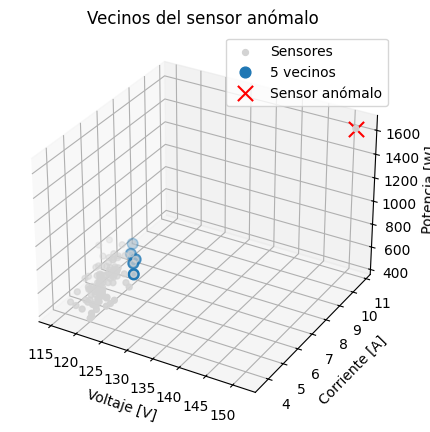

In [9]:

# ---------------------------------------------------------------------------
# 5. FIGURAS
# ---------------------------------------------------------------------------
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(*X_raw.T, c="lightgray", s=18, label="Sensores")
ax.scatter(*X_raw[idx_knn].T, c="tab:blue", s=60, label=f"{K} vecinos")
ax.scatter(*X_raw[idx_anom], c="red", marker="x", s=120, label="Sensor anómalo")
ax.set_xlabel("Voltaje [V]"); ax.set_ylabel("Corriente [A]"); ax.set_zlabel("Potencia [W]")
ax.set_title("Vecinos del sensor anómalo"); ax.legend()


###**3. Análisis**

* Los tres métodos identificaron exactamente los mismos cinco vecinos del
sensor anómalo (muestras 20, 47, 3, 80 y 82) con las mismas distancias, de modo que la precisión fue idéntica (100 % de coincidencia, también al consultar con los 100 sensores). Esto es coherente con que tanto el KNN como el kd-tree son métodos exactos: el kd-tree solo descarta distancias que no pueden mejorar el resultado, sin aproximarlo. Las distancias obtenidas (11.95 a 12.40 desviaciones estándar) muestran además que el sensor 100 está aislado del resto de la red.


* En tiempo de ejecución, el KNN fue el más rápido (21.0 µs por consulta), seguido del kd-tree de scipy (30.6 µs) y del kd-tree propio (477.2 µs, unas 23 veces más lento). Los kd-tree además requieren construir el árbol (0.589 ms el propio y 0.031 ms el de scipy), costo que el KNN no tiene. Con solo 100 puntos en 3 dimensiones, calcular todas las distancias es una operación muy barata con relación al costo computacional y la estructura del árbol no compensa su costo; la diferencia entre los dos kd-tree se debe a que uno de ellos está implementado en Python y el de scipy está compilado en C.

* En facilidad de interpretación, el KNN es más simple: calcula la distancia a todos los sensores y toma los cinco menores. El kd-tree exige comprender cómo se divide el espacio (por la mediana, alternando entre voltaje, corriente y potencia) y cómo se depuran las ramas durante la búsqueda, lo que lo hace más difícil de programar.

###**4. Sistema de monitoreo**

Para una red de 100 sensores como la del taller, el método más adecuado es el KNN por fuerza bruta. Fue el más rápido (21.0 µs por consulta), no requiere construir ni mantener ninguna estructura, entrega el mismo resultado exacto que el kd-tree y es el más sencillo de implementar. Un tiempo de consulta del orden de microsegundos es muy inferior a los periodos de muestreo habituales en monitoreo eléctrico, por lo que cumple de una buena forma el requisito de tiempo real.

Además, en un sistema de monitoreo los datos cambian constantemente, y cada nueva medición obligaría a reconstruir o actualizar el kd-tree, sumando costo computacional con relación a cada consulta. El KNN, al no depender de ninguna estructura previa, se adapta a los datos que se renuevan continuamente, y la identificación de sensores anómalos (como ocurrió en la actividad) se puede ejecutar en cada ciclo de medición.

El kd-tree sería una mejor opción si la red creciera considerablemente. El KNN compara contra los N sensores en cada consulta, por lo que su costo crece linealmente con N. Esta es una razón por la que en redes con miles de sensores se recurre a la estructura kd-tree, siempre con una implementación compilada como la de scipy, ya que el kd-tree propio en Python puro resultó unas 23 veces más lento que el KNN en nuestras pruebas.